# Ejercicio Ridge, Lasso y ElasticNet
Para este ejercicio vas a trabajar con datos de ventas de una empresa que fabrica muebles en España. Esta empresa es una Pyme que demanda conocer de antemano qué ingresos va a tener cada mes, ya que necesita pedir un anticipio a su entidad financiera de cara a poder abastecerse de materia prima al comenzar el mes. Como desconoce cuánto tiene que pedir, tira al alza y acaba pagando muchos intereses. El objetivo es reducir estos gastos.

En las bases de datos de la empresa constan todos los gastos en publicidad y ventas, para cada uno de los meses desde su fundación (hace más de 15 años).

Dado que los presupuestos de marketing se cierran al principio de cada mes, la empresa necesita un modelo predictivo que le anticipe las ventas que conseguirá a final de mes en función de los gastos que realizará en marketing.

Para ello tendrás que utilizar tanto modelos de regresión normales, como regularizados.

1. Carga los datos y realiza un pequeño análisis exploratorio. Mira a ver cómo se relaciona las ventas con el resto de variables.
2. Crea varios modelos y modifica los hiperparámetros necesarios para mejorar el performance del modelo.
3. Interpreta los resultados. Traduce a una fórmula tu mejor modelo (escribir la fórmula simplemente). ¿Cuánto cambian las ventas si aumentamos la inversión en radio un punto más? ¿Y si aumentamos la inversión en TV o periódicos?

## Import libraries 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## Exploratory Data Analysis 

In [8]:
# Lectura datos, relación variables, mapas de correlación...
df = pd.DataFrame(pd.read_csv('data/Advertising.csv'))
df = df.drop(columns='Unnamed: 0')
df

,TV,radio,newpaper,sales
0,230.1,37.8,6s9.2,22100.0
1,44.5,39.3,45.1,10400.0
2,17.2,45.9,69.3,9300.0
3,151.5,41.3,58.5,18500.0
4,180.8,10.8,58.4,12900.0
...,...,...,...,...
195,38.2,3.7,13.8,7600.0
196,94.2,4.9,8.1,9700.0
197,177.0,9.3,6.4,12800.0
198,283.6,42.0,66.2,25500.0


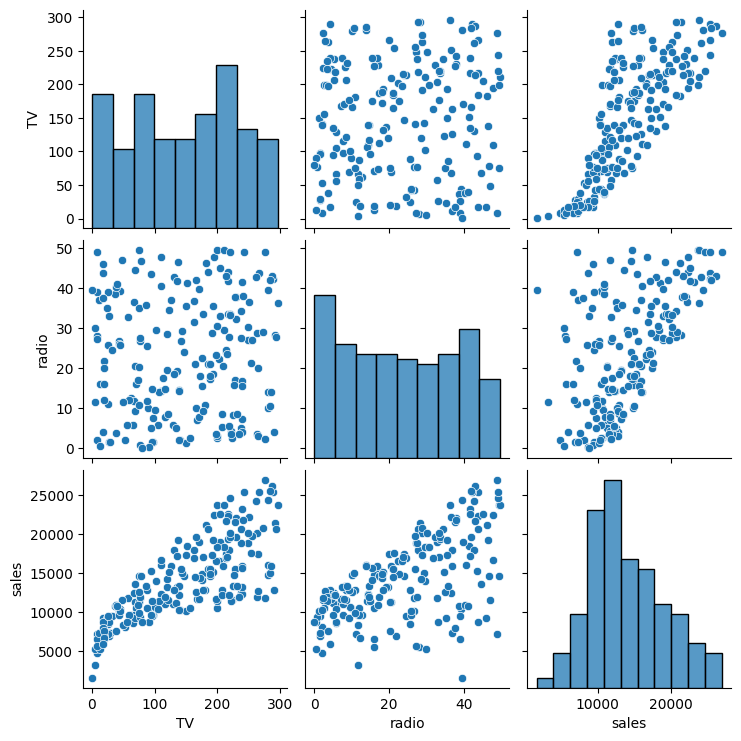

In [9]:
sns.pairplot(df);

In [ ]:

df['newpaper'] = df['newpaper'].str.replace('s', '').astype(float)

df.dtypes  

#arreglar el error de newpaper, habia una s en una fila

TV          float64
radio       float64
newpaper    float64
sales       float64
dtype: object

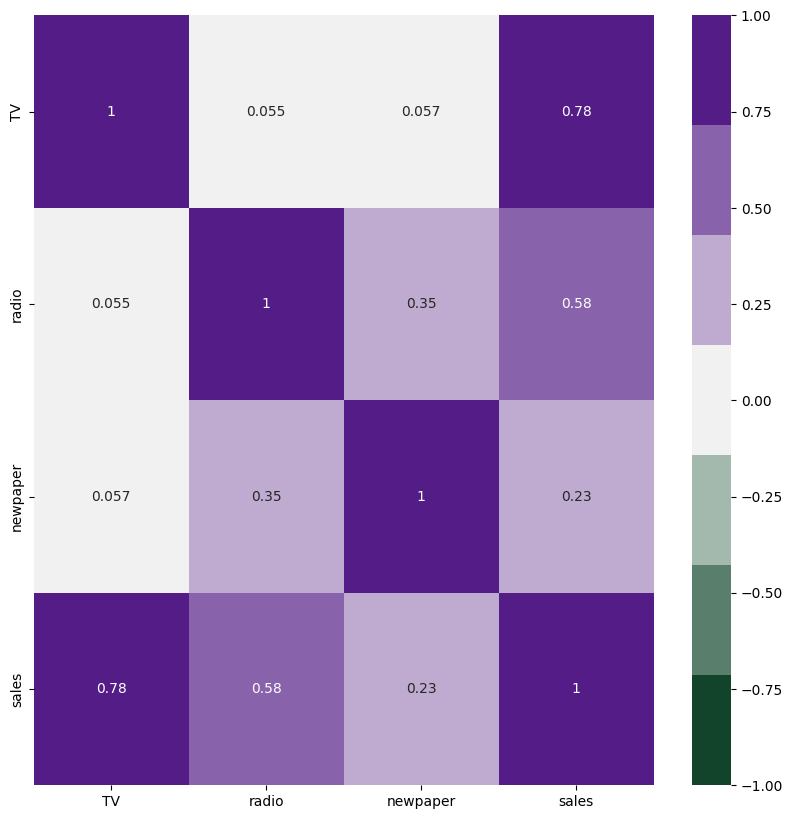

In [14]:
plt.figure(figsize=(10,10))
sns.heatmap(df.corr(),
           vmin=-1,
           vmax=1,
           cmap=sns.diverging_palette(145, 280, s=85, l=25, n=7),
           annot=True);

In [229]:
# Utiliza todas las celdas que necesites...

## Modelado

In [21]:
# Manipulación datasets, entrenamiento, evaluación, nuevas iteraciones... Prueba modelos sin y con regularización.

X = df[['TV', 'radio', 'newpaper']]
Y = df['sales']

In [22]:
# Utiliza todas las celdas que necesites...

X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=666 )
modelo_normal = LinearRegression()



In [25]:
modelo_normal.fit(X_train, y_train)
prediccion = modelo_normal.predict(X_test)

In [ ]:
from sklearn import metrics
comparacion = pd.DataFrame(
 y_test
)
comparacion['prediccion'] = prediccion
comparacion['error'] = comparacion['sales'] - comparacion['prediccion']
print(comparacion)

print('R2:', metrics.r2_score(y_test, prediccion))


       sales    prediccion        error
35   12800.0  17140.652095 -4340.652095
143  10400.0   8889.476582  1510.523418
111  21800.0  21087.920137   712.079863
0    22100.0  20614.559625  1485.440375
119   6600.0   6804.395807  -204.395807
65    9300.0   7828.699972  1471.300028
23   15500.0  16628.931567 -1128.931567
109  19800.0  19659.384246   140.615754
157  10100.0  10154.084181   -54.084181
50   11400.0  12814.602445 -1414.602445
184  17600.0  18617.399277 -1017.399277
7    13200.0  12094.987018  1105.012982
71   12400.0  10691.615220  1708.384780
118  15900.0  15648.307536   251.692464
176  20200.0  19969.383917   230.616083
196   9700.0   8206.479669  1493.520331
181  12200.0  14082.382713 -1882.382713
101  23800.0  23472.739657   327.260343
96   11700.0  12724.059578 -1024.059578
116  12200.0  12036.884136   163.115864
1    10400.0  12260.575584 -1860.575584
75    8700.0  11882.817752 -3182.817752
131  12700.0  15817.995511 -3117.995511
22    5600.0   6558.494463  -958.494463


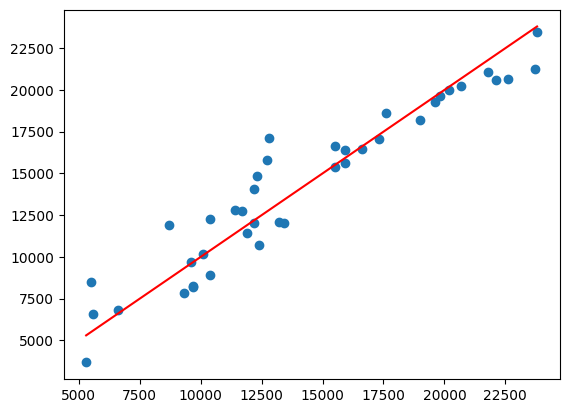

In [29]:
import matplotlib.pyplot as plt
plt.scatter(y_test, prediccion)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red') 

In [ ]:
#Compruebo que hay muy buen R2, pero la grafica veo resultados muy dispersos, y el modelo falla bastante con regresion lineal estándar.

### Modelos Polinómicos

In [30]:
from sklearn.preprocessing import PolynomialFeatures
poly_pyme = PolynomialFeatures(degree = 2)
poly_pyme.fit(X)
X_poly = poly_pyme.transform(X)
X_poly

array([[1.00000e+00, 2.30100e+02, 3.78000e+01, ..., 1.42884e+03,
        2.61576e+03, 4.78864e+03],
       [1.00000e+00, 4.45000e+01, 3.93000e+01, ..., 1.54449e+03,
        1.77243e+03, 2.03401e+03],
       [1.00000e+00, 1.72000e+01, 4.59000e+01, ..., 2.10681e+03,
        3.18087e+03, 4.80249e+03],
       ...,
       [1.00000e+00, 1.77000e+02, 9.30000e+00, ..., 8.64900e+01,
        5.95200e+01, 4.09600e+01],
       [1.00000e+00, 2.83600e+02, 4.20000e+01, ..., 1.76400e+03,
        2.78040e+03, 4.38244e+03],
       [1.00000e+00, 2.32100e+02, 8.60000e+00, ..., 7.39600e+01,
        7.48200e+01, 7.56900e+01]], shape=(200, 10))

In [31]:
X_train_2, X_test_2, y_train_2, y_test_2 = train_test_split(X_poly, Y, test_size = 0.2, random_state=666)
poly_model = LinearRegression()
poly_model.fit(X_train_2, y_train_2)
poly_predict = poly_model.predict(X_test_2)
print('R2:', metrics.r2_score(y_test, poly_predict))

R2: 0.9881499364625422


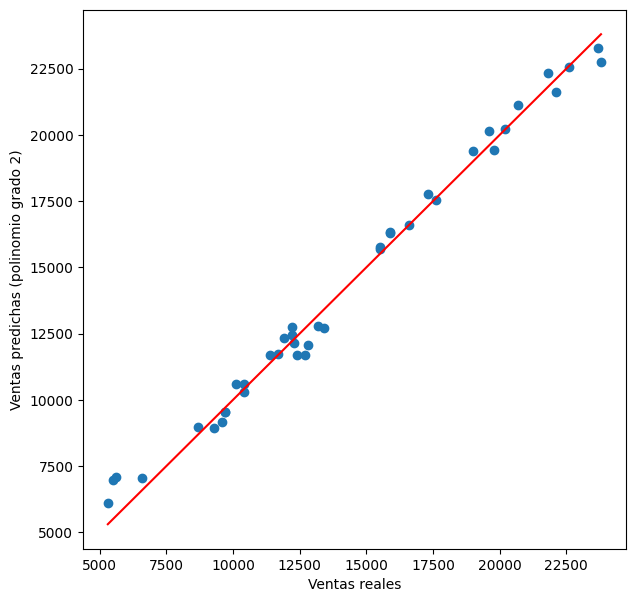

In [32]:
plt.figure(figsize=(7, 7))
plt.scatter(y_test_2, poly_predict)
plt.plot([y_test_2.min(), y_test_2.max()], [y_test_2.min(), y_test_2.max()], color='red')
plt.xlabel('Ventas reales')
plt.ylabel('Ventas predichas (polinomio grado 2)')
plt.show()

R2: 0.99016604032032


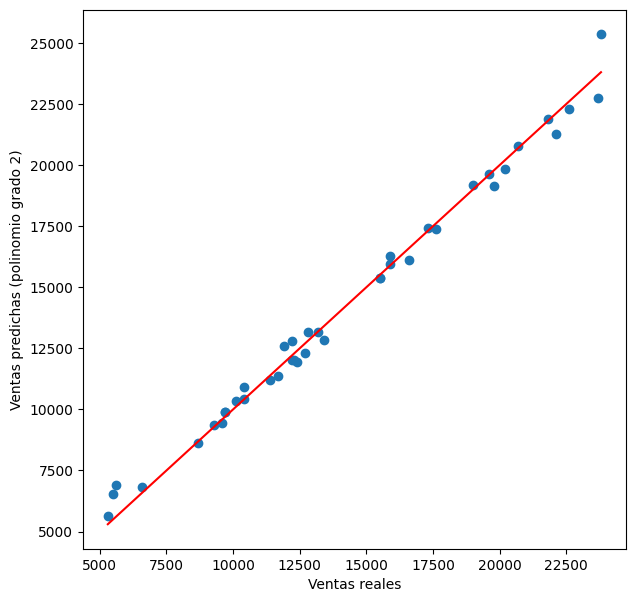

In [34]:
from sklearn.preprocessing import PolynomialFeatures
poly_pyme_2 = PolynomialFeatures(degree = 3)
poly_pyme_2.fit(X)
X_poly_2 = poly_pyme_2.transform(X)
X_poly_2

X_train_3, X_test_3, y_train_3, y_test_3 = train_test_split(X_poly_2, Y, test_size = 0.2, random_state=666)
poly_model_2 = LinearRegression()
poly_model_2.fit(X_train_3, y_train_3)
poly_predict_2 = poly_model_2.predict(X_test_3)
print('R2:', metrics.r2_score(y_test, poly_predict_2))

plt.figure(figsize=(7, 7))
plt.scatter(y_test_3, poly_predict_2)
plt.plot([y_test_3.min(), y_test_3.max()], [y_test_3.min(), y_test_3.max()], color='red')
plt.xlabel('Ventas reales')
plt.ylabel('Ventas predichas (polinomio grado 2)')
plt.show()

## Resultados

In [269]:
# Interpreta, resume y destaca los puntos importantes de los resultados.

In [270]:
# Utiliza todas las celdas que necesites...